# Logistic Regression Classifier from Scratch

## Objective
Implement a binary classification model to predict whether
a student will Pass (1) or Fail (0) based on hours studied.

We will use:
- NumPy for mathematical operations
- Sigmoid function for probability prediction
- Binary Cross-Entropy for calculating loss
- Gradient Descent for optimizing weights

In [2]:
import numpy as np

# Input feature: Hours studied
X = np.array([
    0.5, 0.75, 1, 1.25, 1.5,
    1.75, 2, 2.25, 2.5, 2.75,
    3, 3.25, 3.5, 3.75, 4,
    4.25, 4.5, 4.75, 5
])

# Target variable: Pass (1) or Fail (0)
y = np.array([
    0, 0, 0, 0, 0,
    0, 0, 0, 1, 0,
    1, 0, 1, 1, 1,
    1, 1, 1, 1
])

print("Hours Studied:", X)
print("Pass/Fail:", y)
print("Total Students:", len(X))

Hours Studied: [0.5  0.75 1.   1.25 1.5  1.75 2.   2.25 2.5  2.75 3.   3.25 3.5  3.75
 4.   4.25 4.5  4.75 5.  ]
Pass/Fail: [0 0 0 0 0 0 0 0 1 0 1 0 1 1 1 1 1 1 1]
Total Students: 19


## 2. Sigmoid Function
 
First, the model calculates a linear score:
 
$$
z = wx + b
$$
 
where:
- x is the number of hours studied.
- w is the weight, which controls how study hours affect the score.
- b is the bias, which shifts the score.
 
The sigmoid function converts this score into a probability:
 
$$
p = \sigma(z) = \frac{1}{1 + e^{-z}}
$$
 
A large positive score produces a probability close to 1.
A large negative score produces a probability close to 0.
A score of 0 produces a probability of 0.5.

In [3]:
# Sigmoid activation function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Test the sigmoid function
print(sigmoid(-2))
print(sigmoid(0))
print(sigmoid(2))

0.11920292202211755
0.5
0.8807970779778823


In [4]:
# Initial weight and bias (example values)
w = 0.5
b = -1

# Calculate linear combination
z = w * X + b

# Convert into probabilities
probabilities = sigmoid(z)

# Convert probabilities into Pass/Fail
predictions = (probabilities >= 0.5).astype(int)

# Display results for selected students
for i in [2, 10, 18]:
    print("Hours Studied:", X[i])
    print("Probability of Passing:", round(probabilities[i], 4))
    print("Predicted Result:", predictions[i])
    print("--------------------")

Hours Studied: 1.0
Probability of Passing: 0.3775
Predicted Result: 0
--------------------
Hours Studied: 3.0
Probability of Passing: 0.6225
Predicted Result: 1
--------------------
Hours Studied: 5.0
Probability of Passing: 0.8176
Predicted Result: 1
--------------------


In [5]:
# Binary Cross-Entropy Loss Function
def binary_cross_entropy(y, probabilities):

    # Prevent log(0) errors
    probabilities = np.clip(probabilities, 1e-15, 1 - 1e-15)

    # Calculate loss
    loss = -np.mean(
        y * np.log(probabilities) +
        (1 - y) * np.log(1 - probabilities)
    )

    return loss


# Calculate loss using our previous predictions
loss = binary_cross_entropy(y, probabilities)

print("Binary Cross-Entropy Loss:", loss)

Binary Cross-Entropy Loss: 0.4990725985303193


## 3. Gradient Descent and Model Training

Gradient Descent is an optimization algorithm used to minimize
Binary Cross-Entropy loss.

It updates the weight (w) and bias (b) using the gradients
calculated from the difference between predicted probabilities
and actual results.

The gradients are:

$$
dw = \frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)x_i
$$

$$
db = \frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)
$$

The parameters are updated using:

$$
w = w - \alpha dw
$$

$$
b = b - \alpha db
$$

where alpha is the learning rate.

We repeat these calculations over multiple iterations
to reduce the loss.

In [6]:
# Initialize weight and bias
w = 0.5
b = -1

# Training configuration
learning_rate = 0.1
epochs = 1000

# Store loss values for visualization
loss_history = []

# Gradient Descent training loop
for epoch in range(epochs):

    # Step 1: Calculate linear combination
    z = w * X + b

    # Step 2: Predict probabilities
    probabilities = sigmoid(z)

    # Step 3: Calculate gradients
    dw = np.mean((probabilities - y) * X)
    db = np.mean(probabilities - y)

    # Step 4: Update weight and bias
    w = w - learning_rate * dw
    b = b - learning_rate * db

    # Step 5: Calculate updated loss
    probabilities = sigmoid(w * X + b)
    loss = binary_cross_entropy(y, probabilities)

    # Save loss
    loss_history.append(loss)

    # Display progress every 100 iterations
    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}: Loss = {loss:.4f}")

print("\nTraining Completed!")
print("Final Weight:", round(w, 4))
print("Final Bias:", round(b, 4))
print("Final Loss:", round(loss_history[-1], 4))

Epoch 100: Loss = 0.4043
Epoch 200: Loss = 0.3548
Epoch 300: Loss = 0.3252
Epoch 400: Loss = 0.3058
Epoch 500: Loss = 0.2921
Epoch 600: Loss = 0.2820
Epoch 700: Loss = 0.2744
Epoch 800: Loss = 0.2683
Epoch 900: Loss = 0.2635
Epoch 1000: Loss = 0.2595

Training Completed!
Final Weight: 1.8184
Final Bias: -5.0744
Final Loss: 0.2595


## 4. Model Evaluation

After training the Logistic Regression model, we evaluate
its performance by comparing predicted results with actual results.

The sigmoid function produces probabilities between 0 and 1.

We use a classification threshold of 0.5:

- Probability >= 0.5: Pass (1)
- Probability < 0.5: Fail (0)

Accuracy measures the percentage of correct predictions.

$$
Accuracy = \frac{Correct\ Predictions}{Total\ Predictions} \times 100
$$

In [7]:
# Calculate probabilities using trained weight and bias
z = w * X + b
probabilities = sigmoid(z)

# Convert probabilities to Pass/Fail
predictions = (probabilities >= 0.5).astype(int)

# Calculate accuracy
accuracy = np.mean(predictions == y) * 100

print("Model Evaluation")
print("----------------------------")

# Display results for all students
for i in range(len(X)):
    print(
        f"Student {i+1}: "
        f"Hours = {X[i]}, "
        f"Actual = {y[i]}, "
        f"Predicted = {predictions[i]}, "
        f"Probability = {probabilities[i]:.4f}"
    )

print("----------------------------")
print(f"Model Accuracy: {accuracy:.2f}%")
print(f"Correct Predictions: {np.sum(predictions == y)}")
print(f"Incorrect Predictions: {np.sum(predictions != y)}")

Model Evaluation
----------------------------
Student 1: Hours = 0.5, Actual = 0, Predicted = 0, Probability = 0.0153
Student 2: Hours = 0.75, Actual = 0, Predicted = 0, Probability = 0.0239
Student 3: Hours = 1.0, Actual = 0, Predicted = 0, Probability = 0.0371
Student 4: Hours = 1.25, Actual = 0, Predicted = 0, Probability = 0.0572
Student 5: Hours = 1.5, Actual = 0, Predicted = 0, Probability = 0.0873
Student 6: Hours = 1.75, Actual = 0, Predicted = 0, Probability = 0.1310
Student 7: Hours = 2.0, Actual = 0, Predicted = 0, Probability = 0.1919
Student 8: Hours = 2.25, Actual = 0, Predicted = 0, Probability = 0.2723
Student 9: Hours = 2.5, Actual = 1, Predicted = 0, Probability = 0.3709
Student 10: Hours = 2.75, Actual = 0, Predicted = 0, Probability = 0.4815
Student 11: Hours = 3.0, Actual = 1, Predicted = 1, Probability = 0.5941
Student 12: Hours = 3.25, Actual = 0, Predicted = 1, Probability = 0.6975
Student 13: Hours = 3.5, Actual = 1, Predicted = 1, Probability = 0.7841
Student 

## 5. Training Loss Visualization

The loss curve shows how Binary Cross-Entropy changes
during Gradient Descent.

- X-axis: Training iterations (epochs)
- Y-axis: Binary Cross-Entropy loss

A decreasing loss indicates that the model is learning
better values for its weight and bias.

The goal is to minimize the loss through Gradient Descent.

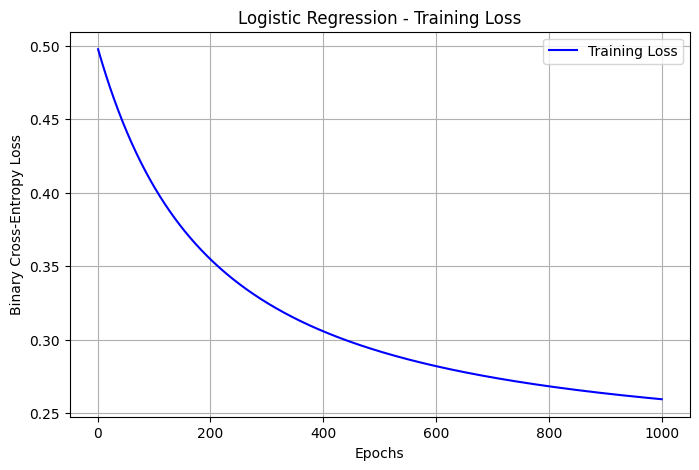

In [8]:
import matplotlib.pyplot as plt

# Plot training loss
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    loss_history,
    label="Training Loss",
    color="blue"
)

plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression - Training Loss")
plt.legend()
plt.grid(True)

plt.show()

## 6. Logistic Regression Classification Visualization

This visualization shows how the trained Logistic Regression
model predicts the probability of passing based on study hours.

- X-axis: Hours studied
- Y-axis: Probability of passing
- Blue curve: Predicted probabilities from the sigmoid function
- Red points: Actual Pass/Fail results
- Green dashed line: Classification threshold of 0.5

If the predicted probability is 0.5 or higher, the model
classifies the student as Pass (1). Otherwise, it predicts Fail (0).

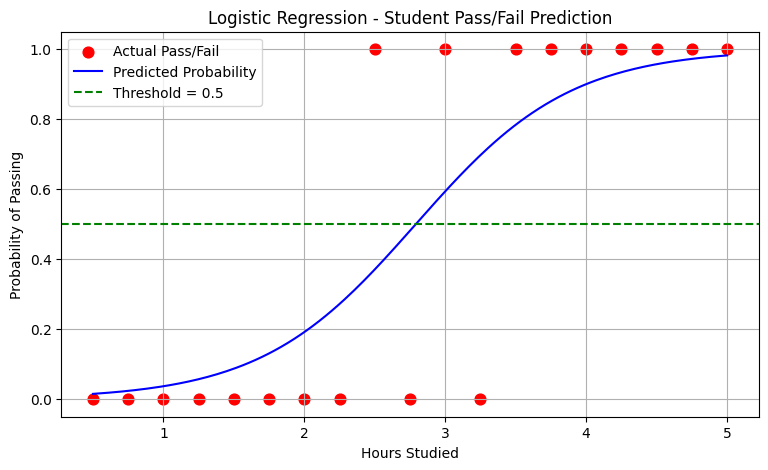

In [9]:
# Generate study hours for a smooth sigmoid curve
X_curve = np.linspace(X.min(), X.max(), 200)

# Calculate probabilities using trained parameters
y_curve = sigmoid(w * X_curve + b)

# Plot
plt.figure(figsize=(9, 5))

# Actual student results
plt.scatter(
    X, y,
    color="red",
    label="Actual Pass/Fail",
    s=60
)

# Logistic Regression sigmoid curve
plt.plot(
    X_curve, y_curve,
    color="blue",
    label="Predicted Probability"
)

# Classification threshold
plt.axhline(
    y=0.5,
    color="green",
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel("Hours Studied")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression - Student Pass/Fail Prediction")

plt.legend()
plt.grid(True)
plt.show()

## Binary Cross-Entropy and Gradient Derivation

### 1. Predicted Probability

For each student, the model calculates:

$$
z_i = wx_i + b
$$

The sigmoid function converts this into a probability:

$$
p_i = \frac{1}{1+e^{-z_i}}
$$

### 2. Binary Cross-Entropy Loss

For n students, the average loss is:

$$
L = -\frac{1}{n}\sum_{i=1}^{n}
[y_i\log(p_i)+(1-y_i)\log(1-p_i)]
$$

This measures the difference between the actual
Pass/Fail labels and predicted probabilities.

### 3. Gradient Derivation

Using the derivative of the sigmoid function and
the chain rule, the derivative of the loss with
respect to the linear score is:

$$
\frac{\partial L_i}{\partial z_i}=p_i-y_i
$$

Since